In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [38]:
train_df=pd.read_csv(r'data/train.csv')
test_df=pd.read_csv(r'data/test.csv')

In [39]:
train_df = train_df.drop(train_df[train_df['Id'].isin([524, 1299])].index)

In [40]:
log_cols = [
    'LotArea',
    'SalePrice',
    'OpenPorchSF'
]

for col in log_cols:
    train_df[col] = np.log1p(train_df[col])

In [41]:
mask = (test_df['Id'] == 2593) & (test_df['GarageYrBlt'] == 2207)

test_df.loc[mask, 'GarageYrBlt'] = test_df.loc[mask, 'YearBuilt']

In [42]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


In [43]:
X = train_df.drop(columns=['SalePrice'])
y = train_df['SalePrice']



In [44]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18004\2340483407.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns


In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1166, 80)
X_test : (292, 80)
y_train: (1166,)
y_test : (292,)


In [46]:
# Xác định kiểu dữ liệu
num_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include=['object']
).columns.tolist()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_18004\2396026804.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


In [47]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Pipeline cho biến số
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline cho biến định tính
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

In [48]:
# Kết hợp preprocessing
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [49]:
# Fit CHỈ trên X_train
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed:", X_train_processed.shape)
print("X_test_processed :", X_test_processed.shape)

X_train_processed: (1166, 300)
X_test_processed : (292, 300)


In [50]:
feature_names = preprocessor.get_feature_names_out()

X_train_scaled = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Số lượng features:", len(feature_names))
print(X_train_scaled.head())

Số lượng features: 300
       num__Id  num__MSSubClass  num__LotFrontage  num__LotArea  \
254  -1.117761        -0.857409          0.017096     -0.159702   
1066  0.810767         0.078786         -0.503746     -0.295247   
865   0.333385        -0.857409         -0.030253     -0.079944   
799   0.176632        -0.155263         -0.456397     -0.460879   
380  -0.818507        -0.155263         -0.929890     -1.173284   

      num__OverallQual  num__OverallCond  num__YearBuilt  num__YearRemodAdd  \
254          -0.781412          0.372581       -0.459933          -1.346989   
1066         -0.053675          1.268311        0.731291           0.447637   
865          -0.781412          0.372581       -0.029769          -0.716444   
799          -0.781412          1.268311       -1.121725          -1.686513   
380          -0.781412          0.372581       -1.551889          -1.686513   

      num__MasVnrArea  num__BsmtFinSF1  ...  cat__SaleType_ConLw  \
254         -0.580392         1

In [51]:
X_train_scaled.columns

Index(['num__Id', 'num__MSSubClass', 'num__LotFrontage', 'num__LotArea',
       'num__OverallQual', 'num__OverallCond', 'num__YearBuilt',
       'num__YearRemodAdd', 'num__MasVnrArea', 'num__BsmtFinSF1',
       ...
       'cat__SaleType_ConLw', 'cat__SaleType_New', 'cat__SaleType_Oth',
       'cat__SaleType_WD', 'cat__SaleCondition_Abnorml',
       'cat__SaleCondition_AdjLand', 'cat__SaleCondition_Alloca',
       'cat__SaleCondition_Family', 'cat__SaleCondition_Normal',
       'cat__SaleCondition_Partial'],
      dtype='str', length=300)

In [52]:
from sklearn.feature_selection import mutual_info_regression, RFE
from sklearn.ensemble import RandomForestRegressor

# =========================================================
# 1. FILTER METHOD - CORRELATION
# =========================================================

corr_with_y = X_train_scaled.apply(
    lambda col: col.corr(y_train)
).abs()

selected_corr = corr_with_y[
    corr_with_y > 0.3
].index.tolist()


# =========================================================
# 2. FILTER METHOD - MUTUAL INFORMATION
# =========================================================

mi_scores = mutual_info_regression(
    X_train_scaled,
    y_train,
    random_state=42
)

mi_series = pd.Series(
    mi_scores,
    index=X_train_scaled.columns
)

selected_mi = mi_series.nlargest(20).index.tolist()


# =========================================================
# 3. WRAPPER METHOD - RFE
# =========================================================

rfe_selector = RFE(
    estimator=RandomForestRegressor(
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    ),
    n_features_to_select=20,
    step=0.1
)

rfe_selector.fit(X_train_scaled, y_train)

selected_rfe = X_train_scaled.columns[
    rfe_selector.support_
].tolist()


# =========================================================
# HIỂN THỊ KẾT QUẢ
# =========================================================

print(
    f"Filter (Correlation > 0.3): "
    f"Chọn {len(selected_corr)} đặc trưng."
)

print(
    f"Filter (Mutual Info Top 20): "
    f"Chọn {len(selected_mi)} đặc trưng."
)

print(
    f"Wrapper (RFE Top 20): "
    f"Chọn {len(selected_rfe)} đặc trưng."
)

Filter (Correlation > 0.3): Chọn 56 đặc trưng.
Filter (Mutual Info Top 20): Chọn 20 đặc trưng.
Wrapper (RFE Top 20): Chọn 20 đặc trưng.


In [53]:
from sklearn.linear_model import LassoCV
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor


# =========================================================
# 1. EMBEDDED METHOD - LASSO
# =========================================================

lasso = LassoCV(
    cv=5,
    random_state=42,
    max_iter=10000
)

lasso.fit(X_train_scaled, y_train)

selected_lasso = X_train_scaled.columns[
    np.abs(lasso.coef_) > 0.005
].tolist()


# =========================================================
# 2. EMBEDDED METHOD - TREE IMPORTANCE
# =========================================================

rf_importance = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_importance.fit(X_train_scaled, y_train)

importances = pd.Series(
    rf_importance.feature_importances_,
    index=X_train_scaled.columns
)

selected_tree = importances.nlargest(20).index.tolist()


# =========================================================
# 3. TẬP CÁC FEATURE
# =========================================================

feature_sets = {
    'All Features (Baseline)': X_train_scaled.columns.tolist(),

    'Filter (Correlation > 0.3)': selected_corr,

    'Filter (Mutual Information Top 20)': selected_mi,

    'Wrapper (RFE Top 20)': selected_rfe,

    'Embedded (Lasso L1)': selected_lasso,

    'Embedded (Tree Importance Top 20)': selected_tree
}


# =========================================================
# 4. ĐỊNH NGHĨA 3 MÔ HÌNH
# =========================================================

models = {
    'SVR (SVM Regression)': SVR(
        C=1.0,
        kernel='rbf'
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'XGBoost': XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        objective='reg:squarederror',
        n_jobs=-1
    )
}


print(
    f"Embedded (Lasso): "
    f"Chọn {len(selected_lasso)} đặc trưng."
)

print(
    f"Embedded (Tree Importance): "
    f"Chọn {len(selected_tree)} đặc trưng."
)

print(
    "Đã thiết lập 3 mô hình và 6 phương pháp Feature Selection!"
)

Embedded (Lasso): Chọn 77 đặc trưng.
Embedded (Tree Importance): Chọn 20 đặc trưng.
Đã thiết lập 3 mô hình và 6 phương pháp Feature Selection!


In [54]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

results = []

# =========================================================
# ĐÁNH GIÁ 6 FEATURE SET × 3 MODEL
# =========================================================

for set_name, features in feature_sets.items():

    if len(features) == 0:
        continue

    X_tr = X_train_scaled[features]
    X_te = X_test_scaled[features]

    for model_name, model in models.items():

        print(
            f"Đang chạy: {set_name} + {model_name}"
        )

        # Train
        model.fit(X_tr, y_train)

        # Predict
        preds = model.predict(X_te)

        # Metrics
        r2 = r2_score(y_test, preds)

        rmse = np.sqrt(
            mean_squared_error(y_test, preds)
        )

        mae = mean_absolute_error(
            y_test,
            preds
        )

        results.append({
            'Feature Selection Method': set_name,
            'Num Features': len(features),
            'Model': model_name,
            'R2 Score': round(r2, 4),
            'RMSE': round(rmse, 4),
            'MAE': round(mae, 4)
        })


# =========================================================
# BẢNG KẾT QUẢ
# =========================================================

results_df = pd.DataFrame(results)

print(
    "\n=== BẢNG SO SÁNH HIỆU SUẤT ==="
)

print(
    results_df.to_string(index=False)
)

Đang chạy: All Features (Baseline) + SVR (SVM Regression)
Đang chạy: All Features (Baseline) + Random Forest
Đang chạy: All Features (Baseline) + XGBoost
Đang chạy: Filter (Correlation > 0.3) + SVR (SVM Regression)
Đang chạy: Filter (Correlation > 0.3) + Random Forest
Đang chạy: Filter (Correlation > 0.3) + XGBoost
Đang chạy: Filter (Mutual Information Top 20) + SVR (SVM Regression)
Đang chạy: Filter (Mutual Information Top 20) + Random Forest
Đang chạy: Filter (Mutual Information Top 20) + XGBoost
Đang chạy: Wrapper (RFE Top 20) + SVR (SVM Regression)
Đang chạy: Wrapper (RFE Top 20) + Random Forest
Đang chạy: Wrapper (RFE Top 20) + XGBoost
Đang chạy: Embedded (Lasso L1) + SVR (SVM Regression)
Đang chạy: Embedded (Lasso L1) + Random Forest
Đang chạy: Embedded (Lasso L1) + XGBoost
Đang chạy: Embedded (Tree Importance Top 20) + SVR (SVM Regression)
Đang chạy: Embedded (Tree Importance Top 20) + Random Forest
Đang chạy: Embedded (Tree Importance Top 20) + XGBoost

=== BẢNG SO SÁNH HIỆU SU

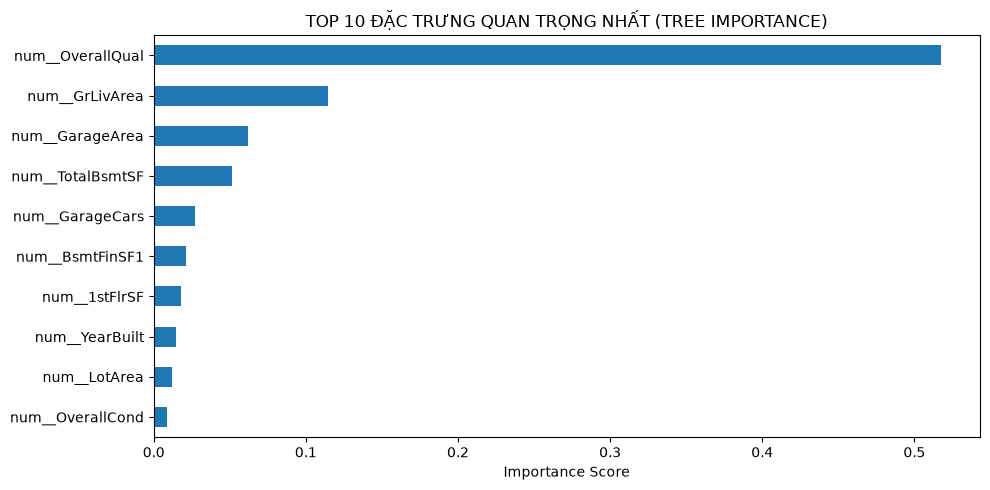

In [55]:
plt.figure(figsize=(10, 5))

importances.nlargest(10).sort_values().plot(
    kind='barh'
)

plt.title(
    'TOP 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT '
    '(TREE IMPORTANCE)'
)

plt.xlabel('Importance Score')

plt.tight_layout()
plt.show()

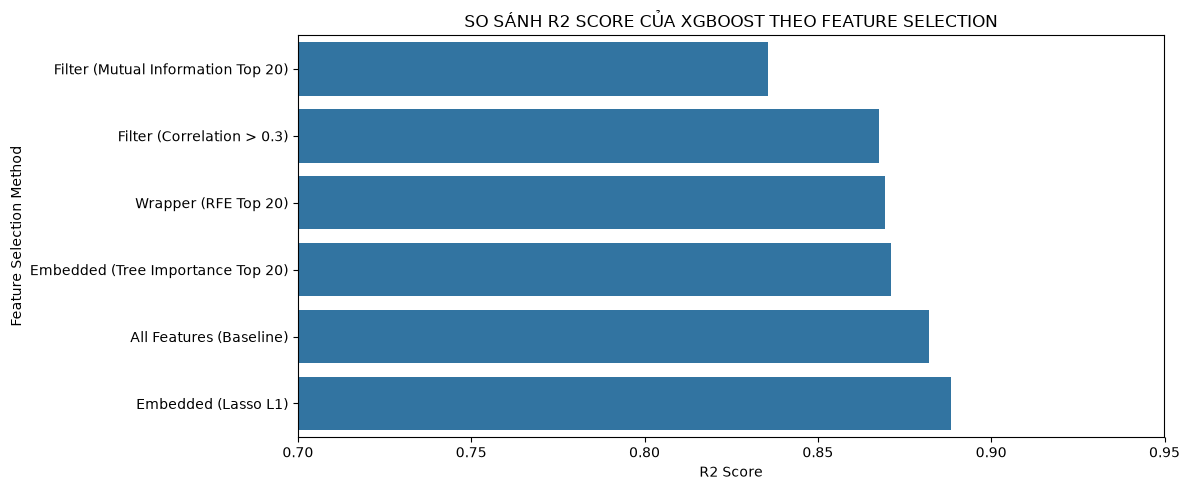

In [56]:
plt.figure(figsize=(12, 5))

xgb_results = results_df[
    results_df['Model'] == 'XGBoost'
].sort_values('R2 Score')

sns.barplot(
    data=xgb_results,
    x='R2 Score',
    y='Feature Selection Method'
)

plt.title(
    'SO SÁNH R2 SCORE CỦA XGBOOST '
    'THEO FEATURE SELECTION'
)

plt.xlim(0.7, 0.95)

plt.tight_layout()
plt.show()

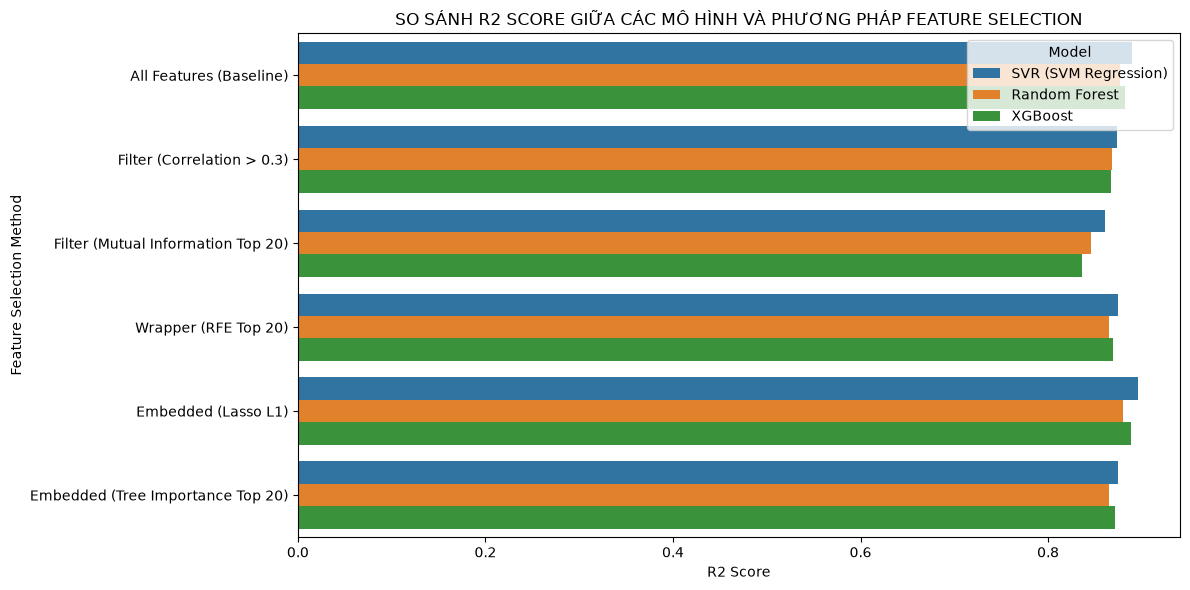

In [57]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='R2 Score',
    y='Feature Selection Method',
    hue='Model'
)

plt.title(
    'SO SÁNH R2 SCORE GIỮA CÁC MÔ HÌNH '
    'VÀ PHƯƠNG PHÁP FEATURE SELECTION'
)

plt.tight_layout()
plt.show()